In [ ]:
%cd /content
!git clone https://github.com/cure-lab/LTSF-Linear.git
%cd /content/LTSF-Linear
!mkdir -p dataset logs/LongForecasting
!wget -q -O dataset/ETTh1.csv https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv
!sed -i 's/np.Inf/np.inf/g' utils/tools.py
!head -2 dataset/ETTh1.csv

/content
Cloning into 'LTSF-Linear'...
remote: Enumerating objects: 393, done.
remote: Counting objects: 100% (198/198), done.
remote: Compressing objects: 100% (90/90), done.
remote: Total 393 (delta 136), reused 108 (delta 108), pack-reused 195 (from 1)
Receiving objects: 100% (393/393), 5.82 MiB | 10.57 MiB/s, done.
Resolving deltas: 100% (195/195), done.
/content/LTSF-Linear
date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
2016-07-01 00:00:00,5.827000141143799,2.009000062942505,1.5989999771118164,0.4620000123977661,4.203000068664552,1.3400000333786009,30.5310001373291


In [ ]:
%cd /content/LTSF-Linear
import subprocess, re, pandas as pd
from google.colab import files

for model in ["DLinear", "NLinear", "Linear"]:
    for T in [96, 192, 336, 720]:
        print("running", model, T)
        subprocess.run(["python", "-u", "run_longExp.py", "--is_training", "1",
            "--root_path", "./dataset/", "--data_path", "ETTh1.csv",
            "--model_id", f"ETTh1_336_{T}", "--model", model, "--data", "ETTh1",
            "--features", "M", "--seq_len", "336", "--pred_len", str(T),
            "--enc_in", "7", "--des", "Exp", "--itr", "3",
            "--batch_size", "32", "--learning_rate", "0.005"],
            stdout=open(f"logs/LongForecasting/{model}_ETTh1_{T}.log", "w"))

rows = {}
lines = open("result.txt").read().split("\n")
for i, l in enumerate(lines[:-1]):
    m = re.match(r"ETTh1_336_(\d+)_(\w+?)_ETTh1_.*_(\d+)\s*$", l)
    r = re.match(r"mse:([\d.]+), mae:([\d.]+)", lines[i + 1])
    if m and r:
        rows[(m[2], int(m[1]), int(m[3]))] = (float(r[1]), float(r[2]))

df = pd.DataFrame([(k[0], k[1], k[2], v[0], v[1]) for k, v in rows.items()],
                  columns=["model", "horizon", "run", "mse", "mae"])
df.to_csv("linear_results.csv", index=False)
print(df.groupby(["model", "horizon"])[["mse", "mae"]].agg(["mean", "std"]).round(4))
files.download("linear_results.csv")
files.download("result.txt")

/content/LTSF-Linear
running DLinear 96
running DLinear 192
running DLinear 336
running DLinear 720
running NLinear 96
running NLinear 192
running NLinear 336
running NLinear 720
running Linear 96
running Linear 192
running Linear 336
running Linear 720
                    mse             mae        
                   mean     std    mean     std
model   horizon                                
DLinear 96       0.3752  0.0077  0.3964  0.0072
        192      0.4280  0.0162  0.4374  0.0153
        336      0.4478  0.0032  0.4486  0.0023
        720      0.5048  0.0299  0.5136  0.0225
Linear  96       0.3730  0.0017  0.3947  0.0019
        192      0.4366  0.0279  0.4460  0.0263
        336      0.4602  0.0165  0.4604  0.0143
        720      0.5409  0.0751  0.5362  0.0509
NLinear 96       0.3730  0.0006  0.3938  0.0004
        192      0.4066  0.0021  0.4142  0.0017
        336      0.4297  0.0013  0.4281  0.0011
        720      0.4375  0.0032  0.4523  0.0012


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%cd /content/LTSF-Linear
import numpy as np, pandas as pd

data = pd.read_csv("dataset/ETTh1.csv").iloc[:, 1:].values   # drop the date column
train = data[:12*30*24]                                       # first 12 months
scaled = (data - train.mean(0)) / train.std(0)                # standardise with train stats only
L = 336
test = scaled[16*30*24 - L : 20*30*24]                        # last 4 months, plus L steps of history

rows = []
for T in [96, 192, 336, 720]:
    n = len(test) - L - T + 1                                 # number of test windows
    y = np.stack([test[L+i : L+i+T] for i in range(n)])       # true futures, shape (n, T, 7)

    # Repeat: forecast = the last observed value, held flat for T steps
    last = test[L-1 : L-1+n]                                  # (n, 7)
    repeat = np.repeat(last[:, None, :], T, axis=1)           # (n, T, 7)

    # Seasonal naive: forecast = the last 24 observed hours, tiled forward
    seasonal = np.stack([
        np.tile(test[L+i-24 : L+i], (T//24 + 1, 1))[:T]
        for i in range(n)
    ])                                                        # (n, T, 7)

    for name, pred in [("Repeat", repeat), ("SeasonalNaive", seasonal)]:
        rows.append((name, T, ((pred - y)**2).mean(), np.abs(pred - y).mean()))

base = pd.DataFrame(rows, columns=["model", "horizon", "mse", "mae"])
base.to_csv("baseline_results.csv", index=False)
print(base.round(4))
from google.colab import files; files.download("baseline_results.csv")

/content/LTSF-Linear
           model  horizon     mse     mae
0         Repeat       96  1.2944  0.7132
1  SeasonalNaive       96  0.5122  0.4333
2         Repeat      192  1.3249  0.7331
3  SeasonalNaive      192  0.5808  0.4692
4         Repeat      336  1.3299  0.7460
5  SeasonalNaive      336  0.6499  0.5008
6         Repeat      720  1.3351  0.7550
7  SeasonalNaive      720  0.6554  0.5141


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%cd /content/LTSF-Linear
# the kernel is hard-coded to 25; make it read the existing --moving_avg flag
!sed -i 's/^        kernel_size = 25$/        kernel_size = configs.moving_avg/' models/DLinear.py
!grep -n "kernel_size" models/DLinear.py | head -3

import subprocess, re, itertools, numpy as np, pandas as pd, time

PRED_LEN = 336          # tuning horizon
_cache, TRIALS = {}, []

def fitness(L, k, lr, tag="x"):
    """Train DLinear with these hyperparameters; return best VALIDATION MSE."""
    L, k = int(L), int(k)
    if k % 2 == 0: k += 1                       # kernel must be odd
    key = (L, k, round(lr, 6))
    if key in _cache: return _cache[key]
    t0 = time.time()
    out = subprocess.run(["python", "-u", "run_longExp.py", "--is_training", "1",
        "--root_path", "./dataset/", "--data_path", "ETTh1.csv",
        "--model_id", f"tune_{tag}_{L}_{k}_{lr:.5f}", "--model", "DLinear", "--data", "ETTh1",
        "--features", "M", "--seq_len", str(L), "--pred_len", str(PRED_LEN),
        "--enc_in", "7", "--des", "Tune", "--itr", "1", "--batch_size", "32",
        "--moving_avg", str(k), "--learning_rate", str(lr)],
        capture_output=True, text=True)
    vals = [float(v) for v in re.findall(r"Vali Loss: ([\d.]+)", out.stdout)]
    score = min(vals) if vals else 9.99         # 9.99 = failed run
    _cache[key] = score
    TRIALS.append({"method": tag, "L": L, "k": k, "lr": lr,
                   "val_mse": score, "secs": round(time.time()-t0, 1)})
    print(f"  [{tag}] L={L:3d} k={k:2d} lr={lr:.5f} -> val {score:.4f}  ({time.time()-t0:.0f}s)")
    return score

# search space
L_RANGE, K_RANGE, LR_RANGE = (48, 720), (5, 75), (1e-4, 1e-2)
def decode(v):                                  # map a fly's [0,1]^3 vector to hyperparameters
    L  = int(round((L_RANGE[0] + v[0]*(L_RANGE[1]-L_RANGE[0])) / 24) * 24)
    k  = int(round((K_RANGE[0] + v[1]*(K_RANGE[1]-K_RANGE[0])) / 2) * 2 + 1)
    lr = 10 ** (np.log10(LR_RANGE[0]) + v[2]*(np.log10(LR_RANGE[1])-np.log10(LR_RANGE[0])))
    return max(L, 48), max(k, 3), lr

print(fitness(336, 25, 0.005, "sanity"))        # should print ≈ the default config's validation loss

/content/LTSF-Linear
10:    def __init__(self, kernel_size, stride):
12:        self.kernel_size = kernel_size
13:        self.avg = nn.AvgPool1d(kernel_size=kernel_size, stride=stride, padding=0)
  [sanity] L=336 k=25 lr=0.00500 -> val 1.0382  (47s)
1.038185


In [ ]:
!sed -n '48p' models/DLinear.py

        kernel_size = configs.moving_avg


In [ ]:
import numpy as np, pandas as pd

# ---------- 1. DFO (adapted from the week 7 lab) ----------
N, D, delta, ITERS = 6, 3, 0.01, 4
np.random.seed(42)
X = np.random.rand(N, D)          # N flies, each a position in 3-D [0,1] space
fit = [0.0] * N

for itr in range(ITERS):
    for i in range(N):
        fit[i] = fitness(*decode(X[i]), "dfo")
    s = int(np.argmin(fit))                               # the swarm's best fly
    print(f"-- DFO iteration {itr}: best validation MSE {fit[s]:.4f}")
    for i in range(N):
        if i == s:
            continue                                      # elitism: the best fly stays put
        left, right = (i-1) % N, (i+1) % N                # ring neighbourhood
        best_nb = right if fit[right] < fit[left] else left
        for d in range(D):
            if np.random.rand() < delta:                  # disturbance: random restart
                X[i, d] = np.random.rand()
                continue
            u = np.random.rand()
            X[i, d] = X[best_nb, d] + u * (X[s, d] - X[i, d])
            X[i, d] = np.clip(X[i, d], 0, 1)              # keep inside the search space

for i in range(N):
    fit[i] = fitness(*decode(X[i]), "dfo")
s = int(np.argmin(fit))
print("DFO best:", decode(X[s]), "->", round(fit[s], 4))

# ---------- 2. Random search, same budget ----------
np.random.seed(7)
for _ in range(30):
    fitness(*decode(np.random.rand(3)), "random")

# ---------- 3. Grid search, same budget ----------
for L in [96, 192, 336, 528, 720]:
    for k in [5, 25, 51]:
        for lr in [0.001, 0.005]:
            fitness(L, k, lr, "grid")

df = pd.DataFrame(TRIALS)
df.to_csv("tuning_trials.csv", index=False)
print(df.groupby("method")["val_mse"].agg(["min", "mean", "count"]).round(4))
from google.colab import files; files.download("tuning_trials.csv")

  [dfo] L=288 k=73 lr=0.00291 -> val 1.0479  (33s)
  [dfo] L=456 k=17 lr=0.00021 -> val 1.0637  (29s)
  [dfo] L= 96 k=67 lr=0.00159 -> val 1.1056  (33s)
  [dfo] L=528 k= 7 lr=0.00871 -> val 1.0624  (49s)
  [dfo] L=600 k=21 lr=0.00023 -> val 1.0861  (45s)
  [dfo] L=168 k=27 lr=0.00112 -> val 1.0879  (34s)
-- DFO iteration 0: best validation MSE 1.0479
  [dfo] L=264 k=77 lr=0.00769 -> val 1.0485  (43s)
  [dfo] L=696 k=11 lr=0.00895 -> val 1.0951  (33s)
  [dfo] L=576 k=77 lr=0.00010 -> val 1.0982  (49s)
  [dfo] L=528 k=77 lr=0.00035 -> val 1.0779  (41s)
  [dfo] L=408 k=77 lr=0.00478 -> val 1.0525  (47s)
-- DFO iteration 1: best validation MSE 1.0479
  [dfo] L=312 k=69 lr=0.00122 -> val 1.0408  (28s)
  [dfo] L= 48 k=77 lr=0.00085 -> val 1.1239  (33s)
  [dfo] L=456 k=75 lr=0.00218 -> val 1.0457  (32s)
  [dfo] L=216 k=73 lr=0.00728 -> val 1.0712  (41s)
  [dfo] L=600 k=71 lr=0.00281 -> val 1.0705  (36s)
-- DFO iteration 2: best validation MSE 1.0408
  [dfo] L=312 k=69 lr=0.00115 -> val 1.0417

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Grid 96 done
Grid 192 done
Grid 336 done
Grid 720 done
Random 96 done
Random 192 done
Random 336 done
Random 720 done
DFO 96 done
DFO 192 done
DFO 336 done
DFO 720 done
                   mse             mae        
                  mean     std    mean     std
config horizon                                
DFO    96       0.3883  0.0173  0.4111  0.0176
       192      0.4156  0.0083  0.4239  0.0082
       336      0.4671  0.0084  0.4666  0.0075
       720      0.5159  0.0124  0.5215  0.0091
Grid   96       0.3735  0.0043  0.3954  0.0045
       192      0.4222  0.0104  0.4324  0.0106
       336      0.4449  0.0032  0.4463  0.0027
       720      0.4982  0.0243  0.5089  0.0186
Random 96       0.3822  0.0147  0.4070  0.0166
       192      0.4183  0.0239  0.4293  0.0250
       336      0.4798  0.0299  0.4773  0.0245
       720      0.4916  0.0134  0.5029  0.0098


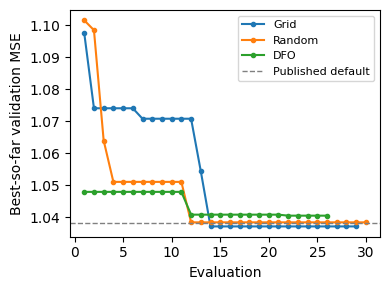

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import re, subprocess, pandas as pd, numpy as np
import matplotlib.pyplot as plt

winners = {"Grid": (336, 5, 0.005), "Random": (360, 31, 0.004740629215115039),
           "DFO": (312, 71, 0.0012756311416711808)}
out = []
for name, (L, k, lr) in winners.items():
    for T in [96, 192, 336, 720]:
        r = subprocess.run(["python", "-u", "run_longExp.py", "--is_training", "1",
            "--root_path", "./dataset/", "--data_path", "ETTh1.csv",
            "--model_id", f"final_{name}_{T}", "--model", "DLinear", "--data", "ETTh1",
            "--features", "M", "--seq_len", str(L), "--pred_len", str(T),
            "--enc_in", "7", "--des", "Final", "--itr", "3", "--batch_size", "32",
            "--moving_avg", str(k), "--learning_rate", str(lr)],
            capture_output=True, text=True)
        for mse, mae in re.findall(r"mse:([\d.]+), mae:([\d.]+)", r.stdout):
            out.append({"config": name, "L": L, "k": k, "lr": lr,
                        "horizon": T, "mse": float(mse), "mae": float(mae)})
        print(name, T, "done")

fin = pd.DataFrame(out)
fin.to_csv("final_test_results.csv", index=False)
print(fin.groupby(["config", "horizon"])[["mse", "mae"]].agg(["mean", "std"]).round(4))

# convergence figure
tr = pd.read_csv("tuning_trials.csv")
plt.figure(figsize=(4, 3))
for m, lab in [("grid", "Grid"), ("random", "Random"), ("dfo", "DFO")]:
    v = tr[tr.method == m]["val_mse"].values
    plt.plot(range(1, len(v) + 1), np.minimum.accumulate(v), marker="o", ms=3, label=lab)
plt.axhline(1.0382, ls="--", c="gray", lw=1, label="Published default")
plt.xlabel("Evaluation"); plt.ylabel("Best-so-far validation MSE")
plt.legend(fontsize=8); plt.tight_layout(); plt.savefig("convergence.pdf")
plt.show()
from google.colab import files
files.download("final_test_results.csv"); files.download("convergence.pdf")

In [ ]:
# ===== DFO with variable delta: self-contained =====
%cd /content
import os
if not os.path.exists("LTSF-Linear"):
    !git clone -q https://github.com/cure-lab/LTSF-Linear.git
%cd /content/LTSF-Linear
!mkdir -p dataset logs/LongForecasting
!test -f dataset/ETTh1.csv || wget -q -O dataset/ETTh1.csv https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv
!sed -i 's/np.Inf/np.inf/g' utils/tools.py
!sed -i 's/^        kernel_size = 25$/        kernel_size = configs.moving_avg/' models/DLinear.py
!sed -n '48p' models/DLinear.py

import subprocess, re, time, numpy as np, pandas as pd
from google.colab import files

PRED_LEN = 336
L_RANGE, K_RANGE, LR_RANGE = (48, 720), (5, 75), (1e-4, 1e-2)
TRIALS, _cache = [], {}

def decode(v):   # identical to yesterday, so results are comparable
    L  = int(round((L_RANGE[0] + v[0]*(L_RANGE[1]-L_RANGE[0])) / 24) * 24)
    k  = int(round((K_RANGE[0] + v[1]*(K_RANGE[1]-K_RANGE[0])) / 2) * 2 + 1)
    lr = 10 ** (np.log10(LR_RANGE[0]) + v[2]*(np.log10(LR_RANGE[1])-np.log10(LR_RANGE[0])))
    return max(L, 48), max(k, 3), lr

def run(L, k, lr, T, itr, tag):
    return subprocess.run(["python", "-u", "run_longExp.py", "--is_training", "1",
        "--root_path", "./dataset/", "--data_path", "ETTh1.csv",
        "--model_id", f"{tag}_{L}_{k}_{lr:.5f}_{T}", "--model", "DLinear", "--data", "ETTh1",
        "--features", "M", "--seq_len", str(L), "--pred_len", str(T),
        "--enc_in", "7", "--des", "Exp", "--itr", str(itr), "--batch_size", "32",
        "--moving_avg", str(k), "--learning_rate", str(lr)],
        capture_output=True, text=True).stdout

def fitness(L, k, lr, tag):
    if k % 2 == 0: k += 1
    key = (tag, L, k, round(lr, 6))
    if key in _cache: return _cache[key]
    t0 = time.time()
    vals = [float(v) for v in re.findall(r"Vali Loss: ([\d.]+)", run(L, k, lr, PRED_LEN, 1, "tune_" + tag))]
    score = min(vals) if vals else 9.99
    _cache[key] = score
    TRIALS.append({"method": tag, "L": L, "k": k, "lr": lr, "val_mse": score,
                   "secs": round(time.time() - t0, 1)})
    pd.DataFrame(TRIALS).to_csv("dfo_variants.csv", index=False)   # saved after every trial
    print(f"  [{tag}] L={L:3d} k={k:2d} lr={lr:.5f} -> val {score:.4f}")
    return score

def dfo(tag, delta_schedule, N=6, D=3, ITERS=4, seed=42):
    np.random.seed(seed)                  # same starting swarm as yesterday
    X = np.random.rand(N, D); fit = [0.0] * N
    for itr in range(ITERS):
        delta = delta_schedule(itr, ITERS)
        for i in range(N):
            fit[i] = fitness(*decode(X[i]), tag)
        s = int(np.argmin(fit))
        print(f"-- [{tag}] iteration {itr}: delta={delta:.3f}, best val {fit[s]:.4f}")
        for i in range(N):
            if i == s: continue                                   # elitism
            left, right = (i - 1) % N, (i + 1) % N                # ring neighbourhood
            nb = right if fit[right] < fit[left] else left
            for d in range(D):
                if np.random.rand() < delta:                      # disturbance
                    X[i, d] = np.random.rand(); continue
                u = np.random.rand()
                X[i, d] = np.clip(X[nb, d] + u * (X[s, d] - X[i, d]), 0, 1)
    for i in range(N):
        fit[i] = fitness(*decode(X[i]), tag)
    s = int(np.argmin(fit))
    return decode(X[s]), fit[s]

decaying      = lambda t, T: 0.2 - (0.2 - 0.01) * t / (T - 1)    # 0.20 -> 0.01
constant_high = lambda t, T: 0.2

results = {"DFO-decay": dfo("dfo_decay", decaying),
           "DFO-0.2":   dfo("dfo_02",    constant_high)}
print(results)

final = []
for name, ((L, k, lr), v) in results.items():
    for T in [96, 192, 336, 720]:
        out = run(L, k, lr, T, 3, "final_" + name)
        for mse, mae in re.findall(r"mse:([\d.]+), mae:([\d.]+)", out):
            final.append({"config": name, "L": L, "k": k, "lr": lr,
                          "horizon": T, "mse": float(mse), "mae": float(mae)})
        print(name, T, "done")
fin = pd.DataFrame(final)
fin.to_csv("final_variants.csv", index=False)
print(fin.groupby(["config", "horizon"])[["mse", "mae"]].agg(["mean", "std"]).round(4))
files.download("dfo_variants.csv"); files.download("final_variants.csv")

/content
/content/LTSF-Linear
        kernel_size = configs.moving_avg
  [dfo_decay] L=288 k=73 lr=0.00291 -> val 1.0479
  [dfo_decay] L=456 k=17 lr=0.00021 -> val 1.0637
  [dfo_decay] L= 96 k=67 lr=0.00159 -> val 1.1056
  [dfo_decay] L=528 k= 7 lr=0.00871 -> val 1.0624
  [dfo_decay] L=600 k=21 lr=0.00023 -> val 1.0861
  [dfo_decay] L=168 k=27 lr=0.00112 -> val 1.0879
-- [dfo_decay] iteration 0: delta=0.200, best val 1.0479
  [dfo_decay] L=264 k=77 lr=0.00769 -> val 1.0485
  [dfo_decay] L=696 k=41 lr=0.00895 -> val 1.0980
  [dfo_decay] L=576 k=73 lr=0.00010 -> val 1.0982
  [dfo_decay] L=528 k=77 lr=0.00098 -> val 1.0908
  [dfo_decay] L=648 k=77 lr=0.00478 -> val 1.0857
-- [dfo_decay] iteration 1: delta=0.137, best val 1.0479
  [dfo_decay] L=312 k=69 lr=0.00122 -> val 1.0408
  [dfo_decay] L= 48 k=19 lr=0.00045 -> val 1.1362
  [dfo_decay] L=456 k=77 lr=0.00609 -> val 1.0656
  [dfo_decay] L=456 k=75 lr=0.00594 -> val 1.0650
  [dfo_decay] L=600 k=71 lr=0.00281 -> val 1.0705
-- [dfo_decay] 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
for seed in [1, 2]:
    for tag, sched in [("fixed001", lambda t, T: 0.01),
                       ("decay", decaying), ("fixed02", constant_high)]:
        (cfg, val) = dfo(f"{tag}_s{seed}", sched, seed=seed)
        print(f"== {tag} seed {seed}: best {cfg} -> {val:.4f}")
files.download("dfo_variants.csv")

  [fixed001_s1] L=336 k=57 lr=0.00010 -> val 1.0908
  [fixed001_s1] L=240 k=17 lr=0.00015 -> val 1.0980
  [fixed001_s1] L=168 k=31 lr=0.00062 -> val 1.0884
  [fixed001_s1] L=408 k=35 lr=0.00235 -> val 1.0552
  [fixed001_s1] L=192 k=67 lr=0.00011 -> val 1.1198
  [fixed001_s1] L=504 k=35 lr=0.00131 -> val 1.0772
-- [fixed001_s1] iteration 0: delta=0.010, best val 1.0552
  [fixed001_s1] L=504 k=15 lr=0.01000 -> val 1.0650
  [fixed001_s1] L=312 k=31 lr=0.00684 -> val 1.0598
  [fixed001_s1] L=504 k=39 lr=0.00357 -> val 1.1062
  [fixed001_s1] L=600 k=11 lr=0.01000 -> val 1.0761
  [fixed001_s1] L=456 k=15 lr=0.01000 -> val 1.0649
-- [fixed001_s1] iteration 1: delta=0.010, best val 1.0552
  [fixed001_s1] L=312 k=45 lr=0.00465 -> val 1.0625
  [fixed001_s1] L=312 k=45 lr=0.00220 -> val 1.0699
  [fixed001_s1] L=360 k=35 lr=0.00187 -> val 1.0533
  [fixed001_s1] L=312 k=49 lr=0.00192 -> val 1.0681
  [fixed001_s1] L=264 k=49 lr=0.00281 -> val 1.0451
-- [fixed001_s1] iteration 2: delta=0.010, best va

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%cd /content
import os
if not os.path.exists("LTSF-Linear"):
    !git clone -q https://github.com/cure-lab/LTSF-Linear.git
%cd /content/LTSF-Linear
!mkdir -p dataset logs/LongForecasting
!test -f dataset/ETTh1.csv || wget -q -O dataset/ETTh1.csv https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv
!sed -i 's/np.Inf/np.inf/g' utils/tools.py
!sed -i 's/^        kernel_size = 25$/        kernel_size = configs.moving_avg/' models/DLinear.py

import subprocess, re, pandas as pd
L, k, lr = 456, 5, 0.002755843364549949
rows = []
for T in [96, 192, 336, 720]:
    out = subprocess.run(["python", "-u", "run_longExp.py", "--is_training", "1",
        "--root_path", "./dataset/", "--data_path", "ETTh1.csv",
        "--model_id", f"final_dfo_s2_{T}", "--model", "DLinear", "--data", "ETTh1",
        "--features", "M", "--seq_len", str(L), "--pred_len", str(T),
        "--enc_in", "7", "--des", "Final", "--itr", "3", "--batch_size", "32",
        "--moving_avg", str(k), "--learning_rate", str(lr)],
        capture_output=True, text=True).stdout
    for mse, mae in re.findall(r"mse:([\d.]+), mae:([\d.]+)", out):
        rows.append({"horizon": T, "mse": float(mse), "mae": float(mae)})
    print(T, "done")
df = pd.DataFrame(rows)
print(df.groupby("horizon")[["mse", "mae"]].agg(["mean", "std"]).round(4))
print("average MSE:", round(df.groupby("horizon")["mse"].mean().mean(), 4))